# IDSSE 02 — check the possession-label rules against the DFL event log

Notebook 01 cleaned the DFL possession flag with duration rules (give back short spells). The open
question: are those rules good, or just blunt? We cannot judge a rule on labels it made itself, so we
need an outside reference: the **DFL event log**, written by people, independent of the tracking flag.

1. read the events and line them up with the tracking frames,
2. turn them into **event turnovers**: team A's last action, then team B's first action, ball live between,
3. score every label rule: does it change team where the event log does (recall), and is each of its
   changes backed by the event log (precision)?
4. variant B: keep only the label's team changes that the event log confirms.

A **control action** = pass or cross attempt (any outcome, also from a restart), shot, interception /
claimed ball, or tackle won with the ball. An unspecified touch (`OtherBallAction`) is not control.
No BAR-ATH data is read; BAR-ATH numbers quoted are the published public-window statistics.

In [1]:
import os, sys
ROOT = os.path.abspath("..") if os.path.basename(os.getcwd()) == "eda" else os.getcwd()
sys.path.insert(0, ROOT)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.idsse import parse, labels, events

FPS = parse.FPS
HOME_VALUE = 1                      # verified in notebook 01
F = {mid: f for mid, f in parse.files().items()}
MATCHES = [r["match"] for r in parse.inventory() if r["usable"] and r["events_ok"]]
M = {mid: parse.load_match(mid, quiet=True) for mid in MATCHES}
EV = {mid: events.read_events(F[mid]["events"], parse.read_matchinfo(F[mid]["info"])) for mid in MATCHES}
CODES = {mid: labels.frame_codes(m, HOME_VALUE) for mid, m in M.items()}
print(len(MATCHES), "matches")

7 matches


## 1. Lining the events up with the frames

Event times are typed in live, so they are off from the tracking by up to a few seconds. Two steps:

- **per match shift**: the offset that puts the most passers on the ball (within 1.5 m);
- **per event snap**: move each control event to the frame within ±2 s where its player is closest to the
  ball (if within 2 m). Without this, only ~40% of passers are on the ball at their event time.

In [2]:
rows, CTL, TOV = [], {}, {}
for mid in MATCHES:
    off, best, at0 = events.estimate_offset(M[mid], EV[mid])
    CTL[mid] = events.control_events(EV[mid], M[mid], off)
    TOV[mid] = events.event_turnovers(CTL[mid], CODES[mid])
    live_min = (CODES[mid] != labels.D).sum() / FPS / 60
    rows.append({"match": mid, "events": len(EV[mid]), "control_events": len(CTL[mid]),
                 "shift_s": round(off, 1), "passer_on_ball_at_shift": round(best, 2),
                 "snapped_%": round(100 * CTL[mid].snapped.mean()),
                 "event_turnovers": len(TOV[mid]),
                 "per_live_min": round(len(TOV[mid]) / live_min, 2)})
sync = pd.DataFrame(rows).set_index("match")
sync

,events,control_events,shift_s,passer_on_ball_at_shift,snapped_%,event_turnovers,per_live_min
match,,,,,,,
J03WMX,1715,1131,-0.8,0.43,94,133,2.34
J03WN1,1363,866,-1.6,0.45,96,148,3.25
J03WOH,1389,944,0.8,0.39,90,131,2.73
J03WOY,1489,1014,1.2,0.42,93,157,3.09
J03WPY,1504,1027,0.2,0.38,88,114,2.10
J03WQQ,1586,1083,0.4,0.46,94,121,2.15
J03WR9,1452,1070,0.4,0.39,90,126,2.22


In [3]:
CTL[MATCHES[0]].action.value_counts().rename("control actions, first match")

action
pass          982
tackle_won     99
claim          29
shot           21
Name: control actions, first match, dtype: int64

The event log has **~133 live turnovers per match, ~2.6 per minute of live play**. Add ~100 restarts
and that is ~4–5 possessions per live minute: the same range as the BAR-ATH public window (~4.2).
The raw tracking flag has ~336 turnovers per match.

## 2. Score each label rule against the event turnovers

- **recall**: share of event turnovers where the label switches to the new team somewhere between A's last
  action and B's first action (±0.5 s);
- **precision**: share of the label's turnovers that fall in such a window, with the right new team.

High recall, low precision = too many changes (noise). Low recall = real turnovers erased.

In [4]:
RULES = [("raw", 0, False)] + [(f"rule 1, tau {t}s", t, False) for t in (1, 1.5, 2, 3)] \
      + [(f"rules 1+2, tau {t}s", t, True) for t in (1, 1.5, 2, 3)]

def possession_stats(c, half):
    sp = labels.spells(c, half)
    pos = sp[sp[:, 2] != labels.D]
    live_min = (c != labels.D).sum() / FPS / 60
    return {"possessions_per_live_min": len(pos) / live_min, "mean_possession_s": pos[:, 4].mean() / FPS}

rows = []
for mid in MATCHES:
    h = M[mid]["half"]
    for name, tau, before_dead in RULES:
        c = labels.give_back(CODES[mid], h, int(round(tau * FPS)), before_dead) if tau else CODES[mid]
        rows.append({"rule": name, **events.turnover_check(c, h, TOV[mid]), **possession_stats(c, h)})
    c = events.event_confirmed_relabel(CODES[mid], h, TOV[mid])
    rows.append({"rule": "variant B: event-confirmed", **events.turnover_check(c, h, TOV[mid]),
                 **possession_stats(c, h)})
res = pd.DataFrame(rows).groupby("rule", sort=False).mean().round(3)
res

,event_turnovers,label_turnovers,recall,precision,possessions_per_live_min,mean_possession_s
rule,,,,,,
raw,132.857,335.857,0.914,0.380,8.383,7.340
"rule 1, tau 1s",132.857,285.000,0.885,0.419,7.407,8.261
"rule 1, tau 1.5s",132.857,249.571,0.829,0.443,6.725,9.068
"rule 1, tau 2s",132.857,221.286,0.783,0.470,6.184,9.856
"rule 1, tau 3s",132.857,176.429,0.696,0.522,5.328,11.454
"rules 1+2, tau 1s",132.857,263.857,0.884,0.452,6.999,8.732
"rules 1+2, tau 1.5s",132.857,219.857,0.827,0.502,6.155,9.902
"rules 1+2, tau 2s",132.857,186.714,0.779,0.554,5.522,11.029
"rules 1+2, tau 3s",132.857,135.714,0.680,0.662,4.550,13.425


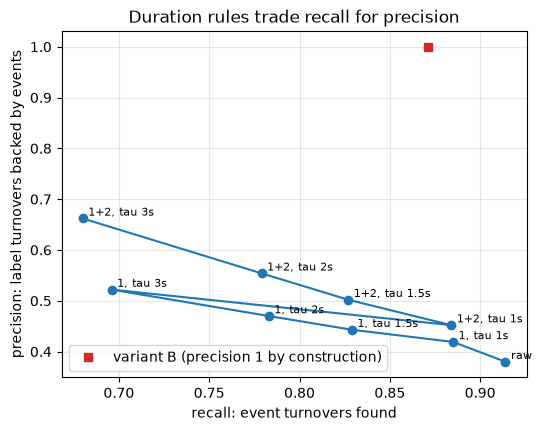

In [5]:
fig, ax = plt.subplots(figsize=(6, 4.5))
dur = res.drop(index="variant B: event-confirmed")
ax.plot(dur.recall, dur.precision, "o-", color="tab:blue")
for name, r in dur.iterrows():
    ax.annotate(name.replace("rules ", "").replace("rule ", ""), (r.recall, r.precision),
                fontsize=8, xytext=(4, 2), textcoords="offset points")
b = res.loc["variant B: event-confirmed"]
ax.plot(b.recall, b.precision, "s", color="tab:red", label="variant B (precision 1 by construction)")
ax.set_xlabel("recall: event turnovers found"); ax.set_ylabel("precision: label turnovers backed by events")
ax.set_title("Duration rules trade recall for precision"); ax.legend(loc="lower left"); ax.grid(alpha=.3)
plt.show()

## Findings

- **The duration rules are a blunt trade-off.** The raw flag finds 91% of the event log's turnovers but
  only 38% of its own changes are backed by an event (the rest are touches, deflections, passes flying
  past someone). Raising τ removes noise **and** real turnovers together: rules 1+2 at τ = 3 s get the
  count right (~136 per match) but erase ~32% of real turnovers and still keep ~34% unbacked changes.
  No τ fixes both, so picking τ was never the real question.
- **Variant B (event-confirmed) does what we wanted:** keep a team change only when the new team makes a
  control action. It keeps 87% of the event log's turnovers and drops the noise. Result: **4.2
  possessions per live minute, mean 14.7 s**. The BAR-ATH public window shows ~4.2 and 14.2 s. Nothing
  was tuned to get there (no τ, no threshold fitted to BAR-ATH), so this is independent support that
  "control action by the new team" matches what the challenge means by controlled possession.
- **Caveats.** Precision is 1 by construction for variant B, so it is not evidence; the evidence is the
  possession rate and length landing on the public window without tuning, and the challenge's own wording
  ("controlled"). Of the 13% of event turnovers it misses, 9 points are turnovers where the tracking flag
  never switches near the event at all (the raw flag's recall is 91%); the rest are confirmed changes that
  became no-ops once the noise around them was dropped. Not yet looked at case by case.

**Decision proposed: train on variant B labels.** Dead ball (`D`) stays the tracking flag's
`BallStatus`. Duration rules are dropped.